In [1]:
# ============================================================
# CELL 1: IMPORTS & CONFIG
# ============================================================
import os
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import tensorflow as tf
from tensorflow.keras import layers, callbacks, regularizers
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score,
    balanced_accuracy_score
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

LABELS = ["Engagement", "Boredom", "Confusion", "Frustration"]
NUM_CLASSES = 4          # ordinal 0-3
SEQ_LEN = 16
EMBED_DIM = 2048

# --- Training config ---
BATCH_SIZE = 32
MAX_EPOCHS = 100
LR = 1e-3
FOCAL_GAMMA = 1.5
EFFECTIVE_NUM_BETA = 0.99     # class-balanced loss hyperparameter (Cui et al. 2019)
                              # lowered from 0.9999 -> less aggressive reweighting now that
                              # rare classes are also merged below (Cell 5), not just reweighted
MACRO_F1_PATIENCE = 15        # stop if avg macro-F1 doesn't improve for this many epochs
MIN_CLASS_FRACTION = 0.03     # any class with < 3% of train samples gets merged into a neighbor

# --- Output locations ---
ARTIFACT_DIR = Path("/kaggle/working/artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = ARTIFACT_DIR / "best_model.keras"
FINAL_MODEL_PATH = ARTIFACT_DIR / "final_model.keras"
SCALER_PATH = ARTIFACT_DIR / "feature_scaler.joblib"
HISTORY_CSV = ARTIFACT_DIR / "training_log.csv"
METRICS_JSON = ARTIFACT_DIR / "test_metrics.json"

print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Artifacts will be saved to:", ARTIFACT_DIR)

GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Artifacts will be saved to: /kaggle/working/artifacts


In [2]:
# ============================================================
# CELL 2: LOCATE THE PREPROCESSED DATASET (robust to whatever
# folder name Kaggle gave your uploaded dataset)
# ============================================================
DATASET_ROOT = Path("/kaggle/input")

def find_array(filename):
    matches = list(DATASET_ROOT.rglob(filename))
    if not matches:
        raise FileNotFoundError(
            f"Could not find '{filename}' anywhere under {DATASET_ROOT}. "
            f"Check that your dataset was actually attached to this notebook "
            f"(Add Data, top right panel)."
        )
    if len(matches) > 1:
        print(f"WARNING: multiple '{filename}' found, using the first: {matches[0]}")
    return matches[0]

X_train = np.load(find_array("X_train.npy"))
y_train = np.load(find_array("y_train.npy"))
X_val   = np.load(find_array("X_val.npy"))
y_val   = np.load(find_array("y_val.npy"))
X_test  = np.load(find_array("X_test.npy"))
y_test  = np.load(find_array("y_test.npy"))

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)

assert X_train.shape[1:] == (SEQ_LEN, EMBED_DIM), (
    f"Expected sequences of shape ({SEQ_LEN}, {EMBED_DIM}), got {X_train.shape[1:]}. "
    f"Update SEQ_LEN/EMBED_DIM in Cell 1 if your preprocessing used different values."
)
assert y_train.shape[1] == len(LABELS)

# Sanity checks that would otherwise silently corrupt training
for name, arr in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    n_nan = np.isnan(arr).sum()
    if n_nan:
        print(f"WARNING: {name} contains {n_nan} NaN values")

for name, y in [("y_train", y_train), ("y_val", y_val), ("y_test", y_test)]:
    lo, hi = y.min(), y.max()
    print(f"{name}: label range [{lo}, {hi}]")
    if lo < 0 or hi > NUM_CLASSES - 1:
        raise ValueError(f"{name} has labels outside [0, {NUM_CLASSES-1}] — check NUM_CLASSES.")

Train: (5358, 16, 2048) (5358, 4)
Val:   (1429, 16, 2048) (1429, 4)
Test:  (1784, 16, 2048) (1784, 4)
y_train: label range [0, 3]
y_val: label range [0, 3]
y_test: label range [0, 3]


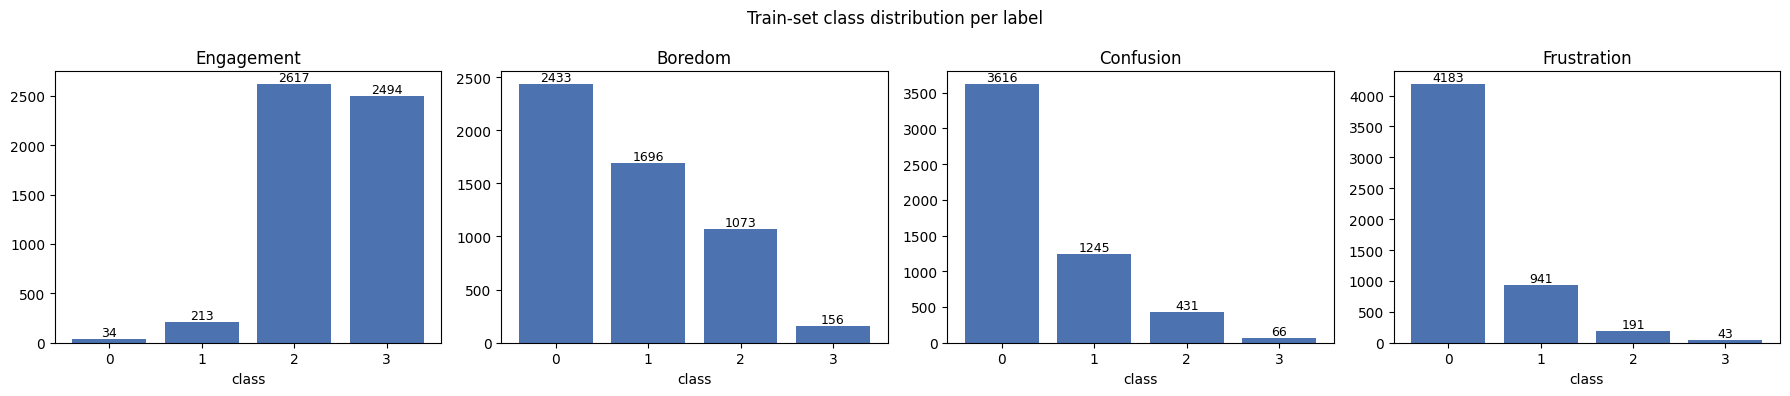

         Engagement  Boredom  Confusion  Frustration
class_0          34     2433       3616         4183
class_1         213     1696       1245          941
class_2        2617     1073        431          191
class_3        2494      156         66           43

Imbalance ratio (majority/minority count) per label:
  Engagement: 77.0x
  Boredom: 15.6x
  Confusion: 54.8x
  Frustration: 97.3x


In [3]:
# ============================================================
# CELL 3: EDA — CLASS DISTRIBUTION (this is *the* thing driving
# the bad F1 scores, so look at it before doing anything else)
# ============================================================
fig, axes = plt.subplots(1, len(LABELS), figsize=(18, 4))
dist_table = {}

for i, label in enumerate(LABELS):
    counts = pd.Series(y_train[:, i]).value_counts().sort_index()
    counts = counts.reindex(range(NUM_CLASSES), fill_value=0)
    dist_table[label] = counts.values
    axes[i].bar(counts.index.astype(str), counts.values, color="#4C72B0")
    axes[i].set_title(label)
    axes[i].set_xlabel("class")
    for j, v in enumerate(counts.values):
        axes[i].text(j, v, str(v), ha="center", va="bottom", fontsize=9)

plt.suptitle("Train-set class distribution per label")
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "train_class_distribution.png", dpi=120)
plt.show()

dist_df = pd.DataFrame(dist_table, index=[f"class_{i}" for i in range(NUM_CLASSES)])
print(dist_df)
print("\nImbalance ratio (majority/minority count) per label:")
for label in LABELS:
    col = dist_df[label]
    nonzero = col[col > 0]
    ratio = nonzero.max() / nonzero.min() if len(nonzero) > 0 else float("nan")
    print(f"  {label}: {ratio:.1f}x")

In [4]:
# ============================================================
# CELL 4: FEATURE SCALING (mask-aware)
# ============================================================
def get_padding_mask(X):
    # A frame is "padding" if the entire 2048-d embedding is exactly zero
    # (this is how the preprocessing notebook padded short sequences).
    return np.all(X == 0.0, axis=-1)   # (N, T) bool, True = padding

mask_train = get_padding_mask(X_train)
mask_val   = get_padding_mask(X_val)
mask_test  = get_padding_mask(X_test)

pad_frac = mask_train.mean()
print(f"Fraction of padded (zero) frames in train: {pad_frac:.1%}")

# Fit scaler only on real (non-padding) train frames
flat_train = X_train.reshape(-1, EMBED_DIM)
flat_mask  = mask_train.reshape(-1)
scaler = StandardScaler()
scaler.fit(flat_train[~flat_mask])

def scale_dataset(X, mask):
    shape = X.shape
    flat = X.reshape(-1, EMBED_DIM)
    flat_scaled = scaler.transform(flat)
    flat_scaled[mask.reshape(-1)] = 0.0   # re-zero padding so Masking still works
    return flat_scaled.reshape(shape).astype(np.float32)

X_train_s = scale_dataset(X_train, mask_train)
X_val_s   = scale_dataset(X_val, mask_val)
X_test_s  = scale_dataset(X_test, mask_test)

joblib.dump(scaler, SCALER_PATH)
print("Scaler saved to", SCALER_PATH)

Fraction of padded (zero) frames in train: 3.9%
Scaler saved to /kaggle/working/artifacts/feature_scaler.joblib


In [5]:
# ============================================================
# CELL 5: AUTOMATIC RARE-CLASS MERGING (per label, data-driven)
# ============================================================
def build_merge_mapping(counts, min_frac=MIN_CLASS_FRACTION):
    total = counts.sum()
    groups = [[i] for i in range(len(counts))]
    group_counts = [float(c) for c in counts]

    changed = True
    while changed and len(groups) > 2:
        changed = False
        for idx, c in enumerate(group_counts):
            if c / total < min_frac:
                if idx < len(groups) - 1:
                    neighbor = idx + 1
                elif idx > 0:
                    neighbor = idx - 1
                else:
                    continue
                lo, hi = min(idx, neighbor), max(idx, neighbor)
                groups = groups[:lo] + [groups[lo] + groups[hi]] + groups[hi + 1:]
                group_counts = (group_counts[:lo]
                                + [group_counts[lo] + group_counts[hi]]
                                + group_counts[hi + 1:])
                changed = True
                break

    mapping = np.zeros(len(counts), dtype=np.int64)
    names = []
    for new_idx, grp in enumerate(groups):
        for orig in grp:
            mapping[orig] = new_idx
        names.append("-".join(str(o) for o in grp))
    return mapping, len(groups), names


merge_maps = {}
num_classes_per_label = {}
class_names_per_label = {}

y_train_m = np.zeros_like(y_train)
y_val_m   = np.zeros_like(y_val)
y_test_m  = np.zeros_like(y_test)

for i, label in enumerate(LABELS):
    counts = np.bincount(y_train[:, i], minlength=NUM_CLASSES)
    mapping, n_new, names = build_merge_mapping(counts)

    merge_maps[label] = mapping
    num_classes_per_label[label] = n_new
    class_names_per_label[label] = names

    y_train_m[:, i] = mapping[y_train[:, i]]
    y_val_m[:, i]   = mapping[y_val[:, i]]
    y_test_m[:, i]  = mapping[y_test[:, i]]

    if n_new < NUM_CLASSES:
        print(f"{label:12s}: merged 4 classes -> {n_new} classes {names}  "
              f"(orig train counts: {counts.tolist()})")
    else:
        print(f"{label:12s}: no merging needed (orig train counts: {counts.tolist()})")

Engagement  : merged 4 classes -> 3 classes ['0-1', '2', '3']  (orig train counts: [34, 213, 2617, 2494])
Boredom     : merged 4 classes -> 3 classes ['0', '1', '2-3']  (orig train counts: [2433, 1696, 1073, 156])
Confusion   : merged 4 classes -> 3 classes ['0', '1', '2-3']  (orig train counts: [3616, 1245, 431, 66])
Frustration : merged 4 classes -> 3 classes ['0', '1', '2-3']  (orig train counts: [4183, 941, 191, 43])


In [6]:
# ============================================================
# CELL 6: LABELS -> ONE-HOT PER HEAD, AND CLASS-BALANCED WEIGHTS
# (using the merged label arrays from Cell 5)
# ============================================================
y_train_oh = {f"{l.lower()}_out": to_categorical(y_train_m[:, i], num_classes_per_label[l])
              for i, l in enumerate(LABELS)}
y_val_oh   = {f"{l.lower()}_out": to_categorical(y_val_m[:, i], num_classes_per_label[l])
              for i, l in enumerate(LABELS)}
y_test_oh  = {f"{l.lower()}_out": to_categorical(y_test_m[:, i], num_classes_per_label[l])
              for i, l in enumerate(LABELS)}

# Keep plain-int (merged) versions around too, for F1 / confusion matrices later
y_val_int  = {f"{l.lower()}_out": y_val_m[:, i]  for i, l in enumerate(LABELS)}
y_test_int = {f"{l.lower()}_out": y_test_m[:, i] for i, l in enumerate(LABELS)}


def effective_number_weights(y_col, num_classes, beta=EFFECTIVE_NUM_BETA):
    """Class-Balanced weighting (Cui et al., CVPR 2019).
    weight_c = (1 - beta) / (1 - beta ** n_c), then normalized to mean 1.
    Handles classes with very few (or zero) samples far more gracefully
    than plain inverse-frequency weighting, which would blow up.
    """
    counts = np.bincount(y_col, minlength=num_classes).astype(np.float64)
    counts = np.maximum(counts, 1)  # avoid div-by-zero for unseen classes
    effective_num = 1.0 - np.power(beta, counts)
    weights = (1.0 - beta) / effective_num
    weights = weights / weights.mean()
    return weights

class_weights = {}
for i, l in enumerate(LABELS):
    w = effective_number_weights(y_train_m[:, i], num_classes_per_label[l])
    class_weights[f"{l.lower()}_out"] = w
    print(f"{l:12s} ({num_classes_per_label[l]} classes) weights: {np.round(w, 2)}")

Engagement   (3 classes) weights: [1.06 0.97 0.97]
Boredom      (3 classes) weights: [1. 1. 1.]
Confusion    (3 classes) weights: [1. 1. 1.]
Frustration  (3 classes) weights: [0.97 0.97 1.07]


In [7]:
# ============================================================
# CELL 6: CLASS-BALANCED FOCAL LOSS + ATTENTION POOLING LAYER
# ============================================================
def make_class_balanced_focal_loss(alpha, gamma=FOCAL_GAMMA):
    """Multi-class focal loss (Lin et al., 2017) with per-class alpha
    from the effective-number-of-samples weighting above.
    """
    alpha = tf.constant(alpha, dtype=tf.float32)

    def loss_fn(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        cross_entropy = -y_true * tf.math.log(y_pred)
        modulating_factor = tf.math.pow(1.0 - y_pred, gamma)
        weighted = alpha * modulating_factor * cross_entropy
        return tf.reduce_sum(weighted, axis=-1)

    return loss_fn


class AttentionPooling(layers.Layer):
    """Additive (Bahdanau-style) attention pooling over the time axis.
    Learns which of the 16 selected frames matter most for each clip,
    instead of only using the LSTM's final hidden state.
    """
    def __init__(self, units, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.supports_masking = True

    def build(self, input_shape):
        feat_dim = input_shape[-1]
        self.W = self.add_weight(name="att_W", shape=(feat_dim, self.units),
                                  initializer="glorot_uniform", trainable=True)
        self.b = self.add_weight(name="att_b", shape=(self.units,),
                                  initializer="zeros", trainable=True)
        self.u = self.add_weight(name="att_u", shape=(self.units, 1),
                                  initializer="glorot_uniform", trainable=True)
        super().build(input_shape)

    def call(self, inputs, mask=None):
        score = tf.tanh(tf.tensordot(inputs, self.W, axes=1) + self.b)   # (B,T,units)
        score = tf.squeeze(tf.tensordot(score, self.u, axes=1), axis=-1)  # (B,T)
        if mask is not None:
            score = score + (1.0 - tf.cast(mask, tf.float32)) * -1e9
        weights = tf.nn.softmax(score, axis=1)                            # (B,T)
        context = tf.reduce_sum(inputs * tf.expand_dims(weights, -1), axis=1)  # (B,F)
        return context

    def compute_mask(self, inputs, mask=None):
        return None   # pooled output has no time dimension left to mask

In [8]:
# ============================================================
# CELL 7: BUILD THE MODEL
# ============================================================
def build_model():
    inputs = layers.Input(shape=(SEQ_LEN, EMBED_DIM), name="embeddings")
    x = layers.Masking(mask_value=0.0)(inputs)

    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(x)
    x = layers.LayerNormalization()(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x)
    x = layers.LayerNormalization()(x)

    context = AttentionPooling(64)(x)

    shared = layers.Dense(128, activation="relu",
                           kernel_regularizer=regularizers.l2(1e-4))(context)
    shared = layers.Dropout(0.4)(shared)

    outputs = []
    for label in LABELS:
        head = layers.Dense(64, activation="relu")(shared)
        head = layers.Dropout(0.3)(head)
        out = layers.Dense(num_classes_per_label[label], activation="softmax",
                            name=f"{label.lower()}_out")(head)
        outputs.append(out)

    return Model(inputs=inputs, outputs=outputs, name="daisee_multitask")


model = build_model()
model.summary()

losses = {f"{l.lower()}_out": make_class_balanced_focal_loss(class_weights[f"{l.lower()}_out"])
          for l in LABELS}

model.compile(
    optimizer=Adam(learning_rate=LR),
    loss=losses,
    metrics={f"{l.lower()}_out": "accuracy" for l in LABELS},
)

I0000 00:00:1783599232.503378      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1783599232.506322      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "daisee_multitask"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ embeddings          │ (None, 16, 2048)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 16, 2048)  │          0 │ embeddings[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masking (Masking)   │ (None, 16, 2048)  │          0 │ embeddings[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any (Any)           │ (None, 16)        │          0 │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 16, 256)   │  2,229,248 │ masking[0][0],    │
│ (Bidirectional)     │                   │            │ any[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 16, 256)   │        512 │ bidirectional[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 16, 256)   │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 16, 128)   │    164,352 │ dropout[0][0],    │
│ (Bidirectional)     │                   │            │ any[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16, 128)   │        256 │ bidirectional_1[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_pooling   │ (None, 128)       │      8,320 │ layer_normalizat… │
│ (AttentionPooling)  │                   │            │ any[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     16,512 │ attention_poolin… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64)        │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 64)        │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ engagement_out      │ (None, 3)         │        195 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                 

 Total params: 2,453,004 (9.36 MB)

 Trainable params: 2,453,004 (9.36 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# ============================================================
# CELL 8: CUSTOM CALLBACK — save whenever avg macro-F1 improves
# (this is what actually fixes "model wasn't saved")
# ============================================================
class MacroF1Checkpoint(callbacks.Callback):
    def __init__(self, X_val, y_val_int, labels, filepath, patience=MACRO_F1_PATIENCE):
        super().__init__()
        self.X_val = X_val
        self.y_val_int = y_val_int
        self.labels = labels
        self.filepath = str(filepath)
        self.patience = patience
        self.best_score = -1.0
        self.wait = 0
        self.history = []

    def on_epoch_end(self, epoch, logs=None):
        preds = self.model.predict(self.X_val, verbose=0)
        if len(self.labels) == 1:
            preds = [preds]

        f1s = {}
        for label, p in zip(self.labels, preds):
            key = f"{label.lower()}_out"
            y_pred = np.argmax(p, axis=1)
            y_true = self.y_val_int[key]
            f1s[label] = f1_score(y_true, y_pred, average="macro", zero_division=0)

        avg_f1 = float(np.mean(list(f1s.values())))
        row = {"epoch": epoch + 1, **f1s, "avg_macro_f1": avg_f1}
        self.history.append(row)

        summary = " ".join(f"{k}={v:.3f}" for k, v in f1s.items())
        print(f"  val_macro_f1 -> {summary} | avg={avg_f1:.3f}")

        if avg_f1 > self.best_score + 1e-4:
            self.best_score = avg_f1
            self.wait = 0
            self.model.save(self.filepath)
            print(f"  -> new best avg macro-F1 ({avg_f1:.4f}), saved to {self.filepath}")
        else:
            self.wait += 1
            if self.wait >= self.patience:
                print(f"  -> no improvement in avg macro-F1 for {self.patience} epochs, stopping.")
                self.model.stop_training = True


macro_f1_ckpt = MacroF1Checkpoint(X_val_s, y_val_int, LABELS, BEST_MODEL_PATH)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1
)

csv_logger = callbacks.CSVLogger(str(HISTORY_CSV), append=False)

In [10]:
# ============================================================
# CELL 9: TRAIN
# (safe to re-run — BEST_MODEL_PATH always holds the best-so-far model,
#  and training_log.csv is written after every single epoch)
# ============================================================
history = model.fit(
    X_train_s, y_train_oh,
    validation_data=(X_val_s, y_val_oh),
    batch_size=BATCH_SIZE,
    epochs=MAX_EPOCHS,
    callbacks=[macro_f1_ckpt, reduce_lr, csv_logger],
    verbose=1,
)

# Always keep a copy of the last-epoch model too, in case you want it
model.save(FINAL_MODEL_PATH)
print("Final (last-epoch) model saved to", FINAL_MODEL_PATH)
print("Best (highest avg macro-F1) model saved to", BEST_MODEL_PATH)

pd.DataFrame(macro_f1_ckpt.history).to_csv(ARTIFACT_DIR / "macro_f1_per_epoch.csv", index=False)

Epoch 1/100
167/168 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - boredom_out_accuracy: 0.4210 - boredom_out_loss: 0.7025 - confusion_out_accuracy: 0.5706 - confusion_out_loss: 0.5621 - engagement_out_accuracy: 0.4564 - engagement_out_loss: 0.5926 - frustration_out_accuracy: 0.6643 - frustration_out_loss: 0.4481 - loss: 2.3179  val_macro_f1 -> Engagement=0.333 Boredom=0.351 Confusion=0.267 Frustration=0.284 | avg=0.309
  -> new best avg macro-F1 (0.3088), saved to /kaggle/working/artifacts/best_model.keras
168/168 ━━━━━━━━━━━━━━━━━━━━ 20s 47ms/step - boredom_out_accuracy: 0.4509 - boredom_out_loss: 0.6101 - confusion_out_accuracy: 0.6219 - confusion_out_loss: 0.4762 - engagement_out_accuracy: 0.5103 - engagement_out_loss: 0.4653 - frustration_out_accuracy: 0.7270 - frustration_out_loss: 0.3601 - loss: 1.9265 - val_boredom_out_accuracy: 0.3842 - val_boredom_out_loss: 0.6311 - val_confusion_out_accuracy: 0.6592 - val_confusion_out_loss: 0.4370 - val_engagement_out_accuracy: 0.4724 - val_engagement

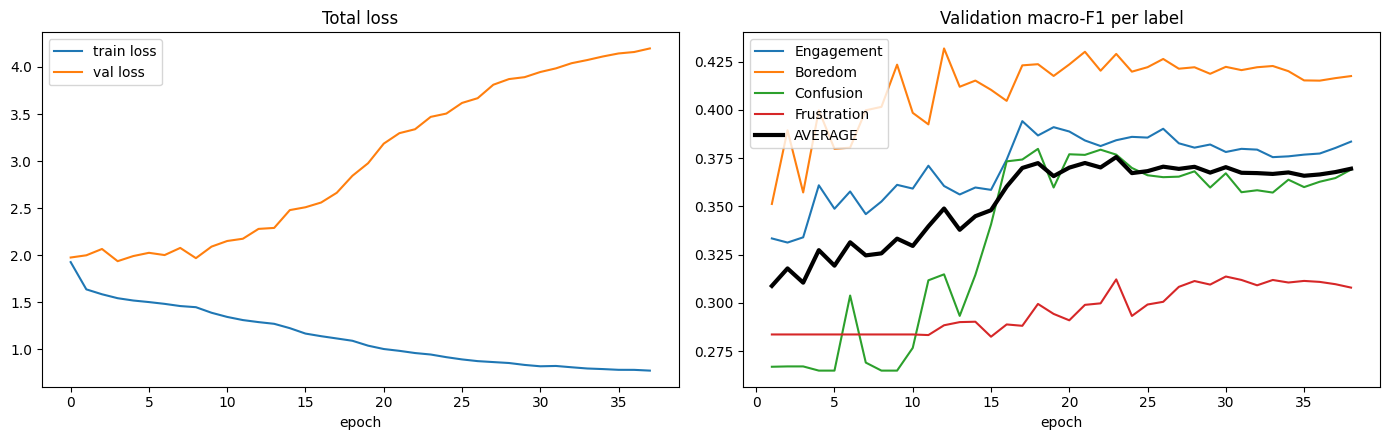

In [11]:
# ============================================================
# CELL 10: TRAINING CURVES
# ============================================================
log_df = pd.read_csv(HISTORY_CSV)
f1_df = pd.read_csv(ARTIFACT_DIR / "macro_f1_per_epoch.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(log_df["epoch"], log_df["loss"], label="train loss")
axes[0].plot(log_df["epoch"], log_df["val_loss"], label="val loss")
axes[0].set_title("Total loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

for label in LABELS:
    axes[1].plot(f1_df["epoch"], f1_df[label], label=label)
axes[1].plot(f1_df["epoch"], f1_df["avg_macro_f1"], label="AVERAGE", linewidth=3, color="black")
axes[1].set_title("Validation macro-F1 per label")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "training_curves.png", dpi=120)
plt.show()


=== Engagement (classes: {0: '0-1', 1: '2', 2: '3'}) ===
              precision    recall  f1-score   support

         0-1       0.13      0.12      0.13        88
           2       0.53      0.56      0.55       882
           3       0.52      0.48      0.50       814

    accuracy                           0.51      1784
   macro avg       0.39      0.39      0.39      1784
weighted avg       0.50      0.51      0.50      1784


=== Boredom (classes: {0: '0', 1: '1', 2: '2-3'}) ===
              precision    recall  f1-score   support

           0       0.53      0.45      0.49       823
           1       0.40      0.43      0.41       584
         2-3       0.25      0.31      0.27       377

    accuracy                           0.41      1784
   macro avg       0.39      0.40      0.39      1784
weighted avg       0.43      0.41      0.42      1784


=== Confusion (classes: {0: '0', 1: '1', 2: '2-3'}) ===
              precision    recall  f1-score   support

           0 

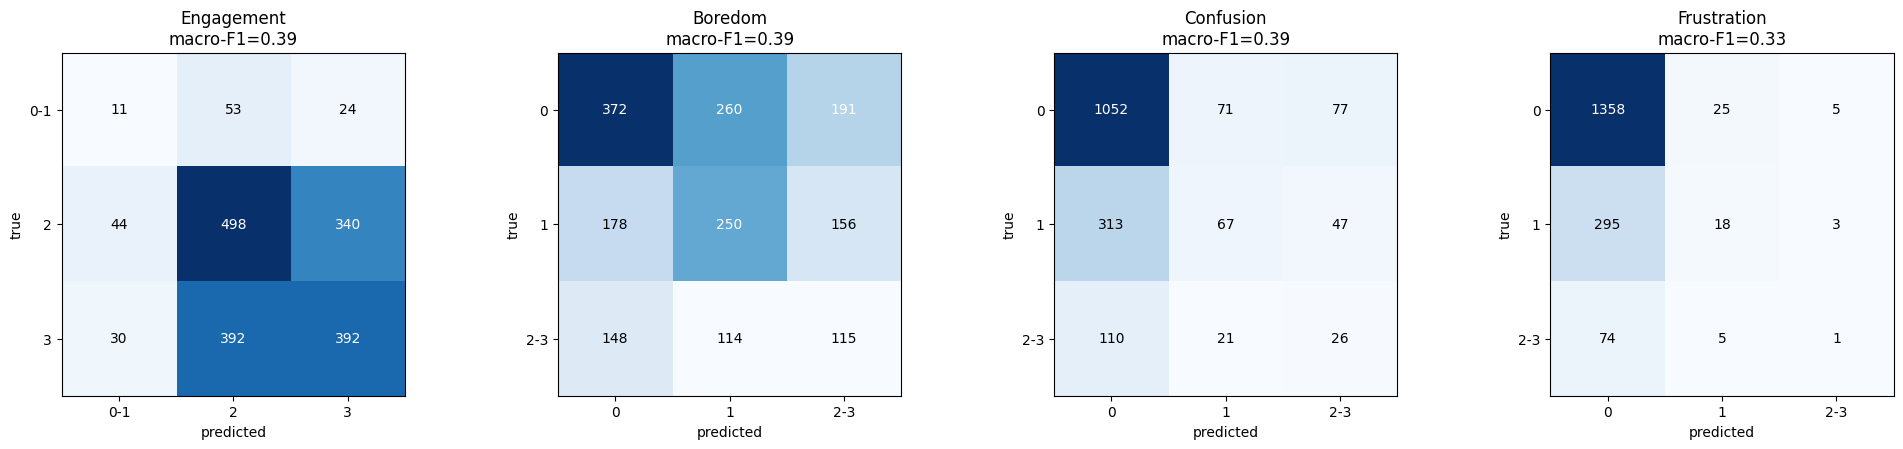


=== OVERALL (mean across 4 labels) macro-F1: 0.377 ===
Full metrics saved to /kaggle/working/artifacts/test_metrics.json


In [12]:
# ============================================================
# CELL 11: EVALUATE THE BEST CHECKPOINT ON THE TEST SET
# ============================================================
best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH,
    custom_objects={
        "AttentionPooling": AttentionPooling,
        "loss_fn": make_class_balanced_focal_loss(class_weights[f"{LABELS[0].lower()}_out"]),
    },
)

test_preds = best_model.predict(X_test_s, verbose=0)
if len(LABELS) == 1:
    test_preds = [test_preds]

all_metrics = {}
fig, axes = plt.subplots(1, len(LABELS), figsize=(20, 4.5))

for i, (label, p) in enumerate(zip(LABELS, test_preds)):
    key = f"{label.lower()}_out"
    y_true = y_test_int[key]
    y_pred = np.argmax(p, axis=1)
    n_cls = num_classes_per_label[label]
    names = class_names_per_label[label]   # e.g. ["0-1", "2", "3"] if 0&1 were merged

    print(f"\n=== {label} (classes: {dict(enumerate(names))}) ===")
    report = classification_report(y_true, y_pred, zero_division=0, output_dict=True,
                                    target_names=names)
    print(classification_report(y_true, y_pred, zero_division=0, target_names=names))

    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    all_metrics[label] = {
        "macro_f1": macro_f1, "weighted_f1": weighted_f1,
        "balanced_accuracy": bal_acc, "report": report,
        "class_names": names,
    }

    cm = confusion_matrix(y_true, y_pred, labels=list(range(n_cls)))
    im = axes[i].imshow(cm, cmap="Blues")
    axes[i].set_title(f"{label}\nmacro-F1={macro_f1:.2f}")
    axes[i].set_xlabel("predicted")
    axes[i].set_ylabel("true")
    axes[i].set_xticks(range(n_cls)); axes[i].set_xticklabels(names)
    axes[i].set_yticks(range(n_cls)); axes[i].set_yticklabels(names)
    for r in range(n_cls):
        for c in range(n_cls):
            axes[i].text(c, r, cm[r, c], ha="center", va="center",
                         color="white" if cm[r, c] > cm.max() / 2 else "black")

plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "confusion_matrices.png", dpi=120)
plt.show()

overall_macro_f1 = np.mean([m["macro_f1"] for m in all_metrics.values()])
print(f"\n=== OVERALL (mean across 4 labels) macro-F1: {overall_macro_f1:.3f} ===")

with open(METRICS_JSON, "w") as f:
    json.dump({"per_label": all_metrics, "overall_macro_f1": overall_macro_f1}, f, indent=2, default=float)
print("Full metrics saved to", METRICS_JSON)

In [13]:
# ============================================================
# CELL 12: SAVE EVERYTHING NEEDED TO REPRODUCE INFERENCE LATER
# ============================================================
config = {
    "labels": LABELS,
    "num_classes_orig": NUM_CLASSES,
    "num_classes_per_label": num_classes_per_label,
    "class_names_per_label": class_names_per_label,
    "merge_maps": {k: v.tolist() for k, v in merge_maps.items()},
    "seq_len": SEQ_LEN,
    "embed_dim": EMBED_DIM,
    "class_weights": {k: v.tolist() for k, v in class_weights.items()},
}
with open(ARTIFACT_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Artifacts directory contents:")
for p in sorted(ARTIFACT_DIR.iterdir()):
    size_kb = p.stat().st_size / 1024
    print(f"  {p.name:35s} {size_kb:9.1f} KB")

print(
    "\nTo run inference later: load BEST_MODEL_PATH with "
    "custom_objects={'AttentionPooling': AttentionPooling, 'loss_fn': <same focal loss>}, "
    "load feature_scaler.joblib, and apply the exact same scale_dataset() masking logic "
    "to new embeddings before calling model.predict()."
)

Artifacts directory contents:
  best_model.keras                      28875.5 KB
  config.json                               1.2 KB
  confusion_matrices.png                   47.0 KB
  feature_scaler.joblib                    48.6 KB
  final_model.keras                     28875.5 KB
  macro_f1_per_epoch.csv                    3.7 KB
  test_metrics.json                         4.7 KB
  train_class_distribution.png             56.9 KB
  training_curves.png                     116.2 KB
  training_log.csv                         14.1 KB

To run inference later: load BEST_MODEL_PATH with custom_objects={'AttentionPooling': AttentionPooling, 'loss_fn': <same focal loss>}, load feature_scaler.joblib, and apply the exact same scale_dataset() masking logic to new embeddings before calling model.predict().
